----

# ¿Cuál es la mejor tarifa?

Trabajas como analista para el operador de telecomunicaciones Megaline. La empresa ofrece a sus clientes dos tarifas de prepago, Surf y Ultimate. El departamento comercial quiere saber cuál de las tarifas genera más ingresos para poder ajustar el presupuesto de publicidad.

Vas a realizar un análisis preliminar de las tarifas basado en una selección de clientes relativamente pequeña. Tendrás los datos de 500 clientes de Megaline: quiénes son los clientes, de dónde son, qué tarifa usan, así como la cantidad de llamadas que hicieron y los mensajes de texto que enviaron en 2018. Tu trabajo es analizar el comportamiento de los clientes y determinar qué tarifa de prepago genera más ingresos.

## Inicio 

In [ ]:
# Cargar todas las librerías
import pandas as pd
import numpy as np
from scipy import stats as st
import seaborn as sns
import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'scipy'

## Cargar datos

In [ ]:
# Carga los archivos de datos en diferentes DataFrames
usuarios = users_df = pd.read_csv('/datasets/megaline_users.csv')
llamadas = calls_df = pd.read_csv('/datasets/megaline_calls.csv')
mensajes = messages_df = pd.read_csv('/datasets/megaline_messages.csv')
internet_mv = internet_df = pd.read_csv('/datasets/megaline_internet.csv')
planes_tarifas = plans_df = pd.read_csv('/datasets/megaline_plans.csv')

## Preparar los datos

Los datos para este proyecto se dividen en varias tablas. Explora cada una para tener una comprensión inicial de los datos. Si es necesario, haz las correcciones requeridas en cada tabla.

## Tarifas

In [ ]:
# Imprime la información general/resumida sobre el DataFrame de las tarifas
planes_tarifas.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      object 
dtypes: float64(2), int64(5), object(1)
memory usage: 256.0+ bytes


In [ ]:
# Imprime una muestra de los datos para las tarifas
planes_tarifas.head()

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


¿Hay algún problema (tipos de datos no adecuados, datos ausentes, etc.) que pudieran necesitar investigación y cambios adicionales? ¿Cómo se puede arreglar?
## Me parece un data set limpio, y con la informacion adecuada, en este caso, no veo la necesidad de hacer ningun cambio o ajuste en los datos.

## Usuarios/as

In [ ]:
# Imprime la información general/resumida sobre el DataFrame de usuarios
usuarios.info()

NameError: name 'usuarios' is not defined

In [ ]:
# Imprime una muestra de datos para usuarios
usuarios.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,1000,Anamaria,Bauer,45,"Atlanta-Sandy Springs-Roswell, GA MSA",2018-12-24,ultimate,NaN
1,1001,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaN
2,1002,Carlee,Hoffman,36,"Las Vegas-Henderson-Paradise, NV MSA",2018-10-21,surf,NaN
3,1003,Reynaldo,Jenkins,52,"Tulsa, OK MSA",2018-01-28,surf,NaN
4,1004,Leonila,Thompson,40,"Seattle-Tacoma-Bellevue, WA MSA",2018-05-23,surf,NaN


 ¿Hay algún problema (tipos de datos no adecuados, datos ausentes, etc.) que pudieran necesitar investigación y cambios adicionales? ¿Cómo se puede arreglar?

## En este dataset, tenemos valores ausentes en la columna 'churm_date' lo cual podria afectar el analisis y sobre todo los datos perderia claridad, la columna 'reg_date' tiene un fromato incorrecto, lo cual puede limitar el acceso a informacion clave en el analisis. 

### Corregir los datos

In [ ]:
usuarios['churn_date']= usuarios['churn_date'].fillna('sin_cancelar')
usuarios['reg_date'] = pd.to_datetime(usuarios['reg_date'])
usuarios.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     500 non-null    int64         
 1   first_name  500 non-null    object        
 2   last_name   500 non-null    object        
 3   age         500 non-null    int64         
 4   city        500 non-null    object        
 5   reg_date    500 non-null    datetime64[ns]
 6   plan        500 non-null    object        
 7   churn_date  500 non-null    object        
dtypes: datetime64[ns](1), int64(2), object(5)
memory usage: 31.4+ KB


## Llamadas

In [ ]:
# Imprime la información general/resumida sobre el DataFrame de las llamadas
llamadas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  object 
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  object 
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 4.2+ MB


In [ ]:
# Imprime una muestra de datos para las llamadas
llamadas.head()

,id,user_id,call_date,duration
0,1000_93,1000,2018-12-27,8.52
1,1000_145,1000,2018-12-27,13.66
2,1000_247,1000,2018-12-27,14.48
3,1000_309,1000,2018-12-28,5.76
4,1000_380,1000,2018-12-30,4.22


 ¿Hay algún problema (tipos de datos no adecuados, datos ausentes, etc.) que pudieran necesitar investigación y cambios adicionales? ¿Cómo se puede arreglar?

## En este dataset, encontre una peculiaridad, la columna 'id' tiene numeros con un gion bajo, por ejemplo 1000_93 esto es algo extraño ya que puede afectar el analisi, una vez mas las fecahs tienen  un formato erroneo. Por ahora se va conservar la columna 'id' tal cual esta, quiza pueda ser de utilidad la informacion depues del guion. 

In [ ]:
llamadas['call_date'] = pd.to_datetime(llamadas['call_date'])
llamadas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   id         137735 non-null  object        
 1   user_id    137735 non-null  int64         
 2   call_date  137735 non-null  datetime64[ns]
 3   duration   137735 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 4.2+ MB


In [ ]:

llamadas_con_guion = llamadas[llamadas['id'].str.contains('_', na=False)]
print(f"Registros con guión bajo: {len(llamadas_con_guion)}")
print(f"Total de registros: {len(llamadas)}")

# Veamos algunos ejemplos
print("\nEjemplos de IDs con guión bajo:")
print(llamadas_con_guion['id'].head(10).tolist())


Registros con guión bajo: 137735
Total de registros: 137735

Ejemplos de IDs con guión bajo:
['1000_93', '1000_145', '1000_247', '1000_309', '1000_380', '1000_388', '1000_510', '1000_521', '1000_530', '1000_544']


In [ ]:
llamadas['id'].head()

0     1000_93
1    1000_145
2    1000_247
3    1000_309
4    1000_380
Name: id, dtype: object

## Mensajes

In [ ]:
# Imprime la información general/resumida sobre el DataFrame de los mensajes
mensajes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            76051 non-null  object
 1   user_id       76051 non-null  int64 
 2   message_date  76051 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.7+ MB


In [ ]:
# Imprime una muestra de datos para los mensajes
mensajes.head()

,id,user_id,message_date
0,1000_125,1000,2018-12-27
1,1000_160,1000,2018-12-31
2,1000_223,1000,2018-12-31
3,1000_251,1000,2018-12-27
4,1000_255,1000,2018-12-26


 ¿Hay algún problema (tipos de datos no adecuados, datos ausentes, etc.) que pudieran necesitar investigación y cambios adicionales? ¿Cómo se puede arreglar?
## En este dataset, tambien debemos considerar la columna 'id' ya que tambien presenta informacion con guión bajo ejemplo 1000_125, tambien se debe corregir la columna 'message_date'

In [ ]:
mensajes['message_date'] = pd.to_datetime(mensajes['message_date'])
mensajes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            76051 non-null  object        
 1   user_id       76051 non-null  int64         
 2   message_date  76051 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 1.7+ MB


In [ ]:
mensajes_con_guion = mensajes[mensajes['id'].str.contains('_', na=False)]
print(f"Registros con guión bajo: {len(mensajes_con_guion)}")
print(f"Total de registros: {len(mensajes)}")

# Veamos algunos ejemplos
print("\nEjemplos de IDs con guión bajo:")
print(mensajes_con_guion['id'].head(10).tolist())

Registros con guión bajo: 76051
Total de registros: 76051

Ejemplos de IDs con guión bajo:
['1000_125', '1000_160', '1000_223', '1000_251', '1000_255', '1000_346', '1000_386', '1000_413', '1000_502', '1000_525']


## Internet

In [ ]:
# Imprime la información general/resumida sobre el DataFrame de internet
internet_mv.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  object 
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  object 
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.2+ MB


In [ ]:
# Imprime una muestra de datos para el tráfico de internet
internet_mv.head()

,id,user_id,session_date,mb_used
0,1000_13,1000,2018-12-29,89.86
1,1000_204,1000,2018-12-31,0.00
2,1000_379,1000,2018-12-28,660.40
3,1000_413,1000,2018-12-26,270.99
4,1000_442,1000,2018-12-27,880.22


 ¿Hay algún problema (tipos de datos no adecuados, datos ausentes, etc.) que pudieran necesitar investigación y cambios adicionales? ¿Cómo se puede arreglar?

## Aqui encontramos de nuvo la columna 'session_date' con un formato erronero, y, encontramos de nuevo la columna 'id' con mueros con guion ejemplo 1000_13

In [ ]:
internet_mv['session_date'] = pd.to_datetime(internet_mv['session_date'])
mensajes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            76051 non-null  object        
 1   user_id       76051 non-null  int64         
 2   message_date  76051 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 1.7+ MB


In [ ]:
internet_mv.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            104825 non-null  object        
 1   user_id       104825 non-null  int64         
 2   session_date  104825 non-null  datetime64[ns]
 3   mb_used       104825 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 3.2+ MB


In [ ]:
id_con_guion = internet_mv[internet_mv['id'].str.contains('_', na=False)]
print(f"Registros con guión bajo: {len(id_con_guion)}")
print(f"Total de registros: {len(internet_mv)}")

# Veamos algunos ejemplos
print("\nEjemplos de IDs con guión bajo:")
print(id_con_guion['id'].head(10).tolist())

Registros con guión bajo: 104825
Total de registros: 104825

Ejemplos de IDs con guión bajo:
['1000_13', '1000_204', '1000_379', '1000_413', '1000_442', '1001_0', '1001_3', '1001_4', '1001_10', '1001_15']


## Estudiar las condiciones de las tarifas

Es sumamente importante entender cómo funcionan las tarifas, cómo se les cobra a los usuarios en función de su plan de suscripción. Así que te sugerimos imprimir la información de la tarifa para ver una vez más sus condiciones.

In [ ]:
# Imprime las condiciones de la tarifa y asegúrate de que te quedan claras
print("Condiciones de las tarifas de Megaline:")
print(planes_tarifas[['usd_monthly_pay', 'plan_name']])

Condiciones de las tarifas de Megaline:
   usd_monthly_pay plan_name
0               20      surf
1               70  ultimate


## Agregar datos por usuario

Ahora que los datos están limpios, agrega los datos por usuario y por periodo para que solo haya un registro por usuario y por periodo. Esto facilitará mucho el análisis posterior.

In [ ]:
# Calcula el número de llamadas hechas por cada usuario al mes. Guarda el resultado.

# Primero crear la columna mes
llamadas['month'] = llamadas['call_date'].dt.month

# Luego agrupar correctamente
llamadas_x_mes = llamadas.groupby(['user_id', 'month']).agg({
    'call_date': 'count'  # CONTAR llamadas, no sumar duración
}).rename(columns={'call_date': 'num_llamadas'})
print(llamadas_x_mes)



               num_llamadas
user_id month              
1000    12               16
1001    8                27
        9                49
        10               65
        11               64
...                     ...
1498    12               39
1499    9                41
        10               53
        11               45
        12               65

[2258 rows x 1 columns]


In [ ]:
llamadas['duration_rounded'] = np.ceil(llamadas['duration'])

In [ ]:
# Calcula la cantidad de minutos usados por cada usuario al mes. Guarda el resultado.
minutos_x_mes = llamadas.groupby(['user_id', 'month']).agg({'duration_rounded':'sum'}).rename(columns={'duration_rounded': 'minutos_totales'})
print(minutos_x_mes)


               minutos_totales
user_id month                 
1000    12               124.0
1001    8                182.0
        9                315.0
        10               393.0
        11               426.0
...                        ...
1498    12               339.0
1499    9                346.0
        10               385.0
        11               308.0
        12               496.0

[2258 rows x 1 columns]


In [ ]:
# Calcula el número de mensajes enviados por cada usuario al mes. Guarda el resultado.
#crear la columna mes 
mensajes['month'] = mensajes['message_date'].dt.month

# Luego agrupar correctamente
mensajes_por_ms = mensajes.groupby(['user_id', 'month']).agg({
    'message_date': 'count'  # CONTAR mensajes 
}).rename(columns={'message_date': 'num_mensajes'})
print(mensajes_por_ms)

               num_mensajes
user_id month              
1000    12               11
1001    8                30
        9                44
        10               53
        11               36
...                     ...
1496    9                21
        10               18
        11               13
        12               11
1497    12               50

[1806 rows x 1 columns]


In [ ]:
# Calcula el volumen del tráfico de Internet usado por cada usuario al mes. Guarda el resultado.
#crear la columna mes 

internet_mv['month'] = internet_mv['session_date'].dt.month

# Luego agrupar correctamente
mb_mensuales = internet_mv.groupby(['user_id', 'month']).agg({
    'mb_used': 'sum'  # SUMAR mb mensuales 
}).rename(columns={'mb_used': 'mb_mensuales'})
mb_mensuales['gb_mensuales'] = np.ceil(mb_mensuales['mb_mensuales'] / 1024)
print(mb_mensuales)  # Usa el nombre correcto de la variable


               mb_mensuales  gb_mensuales
user_id month                            
1000    12          1901.47           2.0
1001    8           6919.15           7.0
        9          13314.82          14.0
        10         22330.49          22.0
        11         18504.30          19.0
...                     ...           ...
1498    12         23137.69          23.0
1499    9          12984.76          13.0
        10         19492.43          20.0
        11         16813.83          17.0
        12         22059.21          22.0

[2277 rows x 2 columns]


Junta los datos agregados en un DataFrame para que haya un registro que represente lo que consumió un usuario único en un mes determinado.

In [ ]:
# Fusiona los datos de llamadas, minutos, mensajes e Internet con base en user_id y month

datos_completos = llamadas_x_mes.merge(
    minutos_x_mes, on=['user_id', 'month'],how='outer'
).merge(
    mb_mensuales, on=['user_id', 'month'],how='outer'
).merge(
    mensajes_por_ms, on=['user_id', 'month'],how='outer'
).merge(
    usuarios, on='user_id'  
)

print(datos_completos.head())

   user_id  num_llamadas  minutos_totales  mb_mensuales  gb_mensuales  \
0     1000          16.0            124.0       1901.47           2.0   
1     1001          27.0            182.0       6919.15           7.0   
2     1001          49.0            315.0      13314.82          14.0   
3     1001          65.0            393.0      22330.49          22.0   
4     1001          64.0            426.0      18504.30          19.0   

   num_mensajes first_name  last_name  age  \
0          11.0   Anamaria      Bauer   45   
1          30.0     Mickey  Wilkerson   28   
2          44.0     Mickey  Wilkerson   28   
3          53.0     Mickey  Wilkerson   28   
4          36.0     Mickey  Wilkerson   28   

                                    city   reg_date      plan    churn_date  
0  Atlanta-Sandy Springs-Roswell, GA MSA 2018-12-24  ultimate  sin_cancelar  
1        Seattle-Tacoma-Bellevue, WA MSA 2018-08-13      surf  sin_cancelar  
2        Seattle-Tacoma-Bellevue, WA MSA 2018-08-1

In [ ]:
# Añade la información de la tarifa
datos_completos = datos_completos.rename(columns={'plan': 'plan_name'})
print()
print(datos_completos.columns)


Index(['user_id', 'num_llamadas', 'minutos_totales', 'mb_mensuales',
       'gb_mensuales', 'num_mensajes', 'first_name', 'last_name', 'age',
       'city', 'reg_date', 'plan_name', 'churn_date'],
      dtype='object')


In [ ]:
datos_completos = datos_completos.merge(
    planes_tarifas, on =['plan_name'])
print(datos_completos)

      user_id  num_llamadas  minutos_totales  mb_mensuales  gb_mensuales  \
0        1000          16.0            124.0       1901.47           2.0   
1        1006           2.0             10.0       2068.37           3.0   
2        1006           9.0             59.0      32118.82          32.0   
3        1008          71.0            476.0      17106.99          17.0   
4        1008          63.0            446.0      23676.72          24.0   
...       ...           ...              ...           ...           ...   
2288     1194           NaN              NaN      42866.10          42.0   
2289     1194           NaN              NaN      31088.49          31.0   
2290     1349           NaN              NaN      13093.55          13.0   
2291     1349           NaN              NaN      17128.26          17.0   
2292     1349           NaN              NaN      13039.91          13.0   

      num_mensajes  first_name last_name  age  \
0             11.0    Anamaria     Bau

Calcula los ingresos mensuales por usuario (resta el límite del paquete gratuito del número total de llamadas, mensajes de texto y datos; multiplica el resultado por el valor del plan de llamadas; añade la tarifa mensual en función del plan de llamadas). Nota: Dadas las condiciones del plan, ¡esto podría no ser tan trivial como un par de líneas! Así que no pasa nada si dedicas algo de tiempo a ello.

In [ ]:

# Calcula el ingreso mensual para cada usuario

def calcular_revenue(row):
    plan = row['plan_name']
    if plan=='surf':
        monthly_fee = 20
        minutes_included =500
        messages_included = 50
        gb_included = 15
        cost_per_minute = 0.03
        cost_per_message = 0.03
        cost_per_gb = 10
    else:    #ultimate
        monthly_fee =70
        minutes_included = 3000
        messages_included = 1000
        gb_included = 30
        cost_per_minute = 0.01
        cost_per_message = 0.01
        cost_per_gb = 7

    minutos = row['minutos_totales'] if pd.notna(row['minutos_totales']) else 0
    mensajes = row['num_mensajes'] if pd.notna(row['num_mensajes']) else 0
    gb = row['gb_mensuales'] if pd.notna(row['gb_mensuales']) else 0
    
    excess_minutes = max(0, minutos - minutes_included)    
    excess_message = max(0, mensajes - messages_included)  
    excess_gb = max(0, gb - gb_included)    
     

    

    revenue = (monthly_fee +
              excess_minutes * cost_per_minute +
              excess_message * cost_per_message+
              excess_gb * cost_per_gb)

    return revenue

datos_completos['revenue'] = datos_completos.apply(calcular_revenue, axis=1)  

print(datos_completos[['user_id', 'plan_name', 'revenue']].head())



   user_id plan_name  revenue
0     1000  ultimate     70.0
1     1006  ultimate     70.0
2     1006  ultimate     84.0
3     1008  ultimate     70.0
4     1008  ultimate     70.0


## Estudia el comportamiento de usuario

Calcula algunas estadísticas descriptivas para los datos agregados y fusionados que nos sean útiles y que muestren un panorama general captado por los datos. Dibuja gráficos útiles para facilitar la comprensión. Dado que la tarea principal es comparar las tarifas y decidir cuál es más rentable, las estadísticas y gráficas deben calcularse por tarifa.

En los comentarios hallarás pistas relevantes para las llamadas, pero no las hay para los mensajes e Internet. Sin embargo, el principio del estudio estadístico que se aplica para ellos es el mismo que para las llamadas.

### Llamadas

In [ ]:
# Compara la duración promedio de llamadas por cada plan y por cada mes. Traza un gráfico de barras para visualizarla.

print(datos_completos['plan_name'].unique())
print(datos_completos['plan_name'].value_counts())

plan_surf = datos_completos[datos_completos['plan_name'] == 'surf']
plan_ultimate = datos_completos[datos_completos['plan_name'] == 'ultimate']



['ultimate' 'surf']
surf        1573
ultimate     720
Name: plan_name, dtype: int64


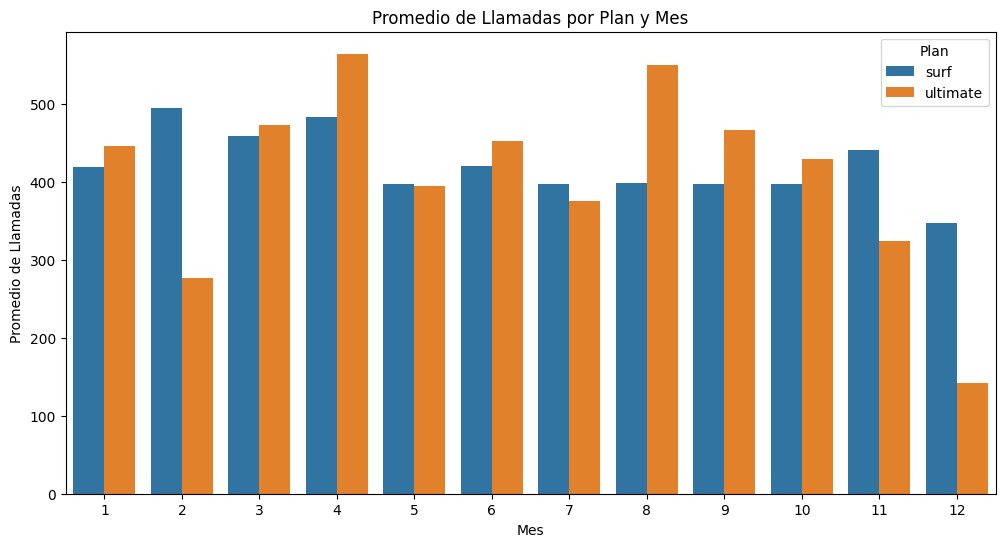

In [ ]:

datos_completos['month'] = datos_completos['reg_date'].dt.month
promedio_minutos = datos_completos.groupby(['month', 'plan_name'])['minutos_totales'].mean().reset_index()
plt.figure(figsize=(12, 6))
sns.barplot(data=promedio_minutos, x='month', y='minutos_totales', hue='plan_name')
plt.title('Promedio de Llamadas por Plan y Mes')
plt.xlabel('Mes')
plt.ylabel('Promedio de Llamadas')
plt.legend(title='Plan')
plt.show()


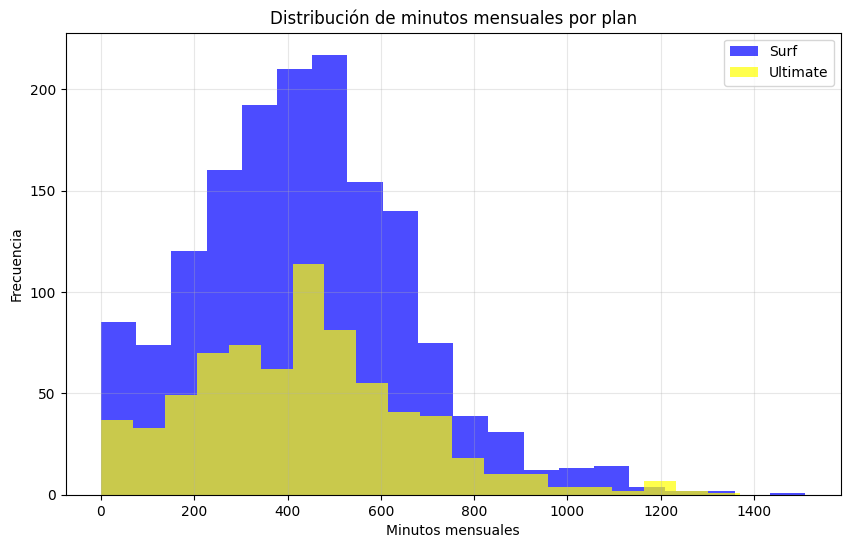

In [ ]:
# Compara el número de minutos mensuales que necesitan los usuarios de cada plan. Traza un histograma.

plt.figure(figsize=(10, 6))

# Histograma para plan Surf
plt.hist(plan_surf['minutos_totales'], bins=20, alpha=0.7, label='Surf', color='blue')

# Histograma para plan Ultimate  
plt.hist(plan_ultimate['minutos_totales'], bins=20, alpha=0.7, label='Ultimate', color='yellow')

plt.xlabel('Minutos mensuales')
plt.ylabel('Frecuencia')
plt.title('Distribución de minutos mensuales por plan')
plt.legend()
plt.grid(True, alpha=0.3)

Calcula la media y la variable de la duración de las llamadas para averiguar si los usuarios de los distintos planes se comportan de forma diferente al realizar sus llamadas.

In [ ]:
# Calcula la media y la varianza de la duración mensual de llamadas.

print("=== PLAN SURF ===")
media_surf = plan_surf['minutos_totales'].mean()
varianza_surf = plan_surf['minutos_totales'].var()
desviacion_surf = plan_surf['minutos_totales'].std()

print(f'Media: {media_surf:.2f} minutos')
print(f'Varianza: {varianza_surf:.2f}')
print(f'Desviación estándar: {desviacion_surf:.2f}')

print("\n=== PLAN ULTIMATE ===")
media_ultimate = plan_ultimate['minutos_totales'].mean()
varianza_ultimate = plan_ultimate['minutos_totales'].var()
desviacion_ultimate = plan_ultimate['minutos_totales'].std()

print(f'Media: {media_ultimate:.2f} minutos')
print(f'Varianza: {varianza_ultimate:.2f}')
print(f'Desviación estándar: {desviacion_ultimate:.2f}')

=== PLAN SURF ===
Media: 436.52 minutos
Varianza: 52571.06
Desviación estándar: 229.28

=== PLAN ULTIMATE ===
Media: 434.68 minutos
Varianza: 56573.63
Desviación estándar: 237.85


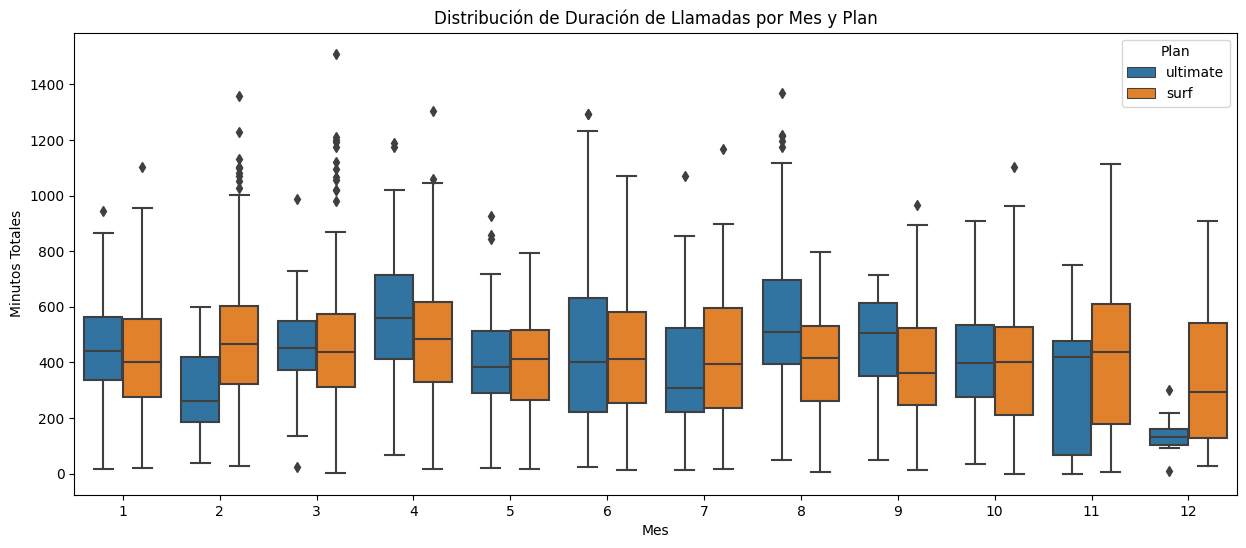

In [ ]:
# Traza un diagrama de caja para visualizar la distribución de la duración mensual de llamadas

datos_completos['month'] = datos_completos['reg_date'].dt.month

# Diagrama de caja por plan y mes
plt.figure(figsize=(15, 6))
sns.boxplot(data=datos_completos, x='month', y='minutos_totales', hue='plan_name')
plt.title('Distribución de Duración de Llamadas por Mes y Plan')
plt.xlabel('Mes')
plt.ylabel('Minutos Totales')
plt.legend(title='Plan')
plt.show()

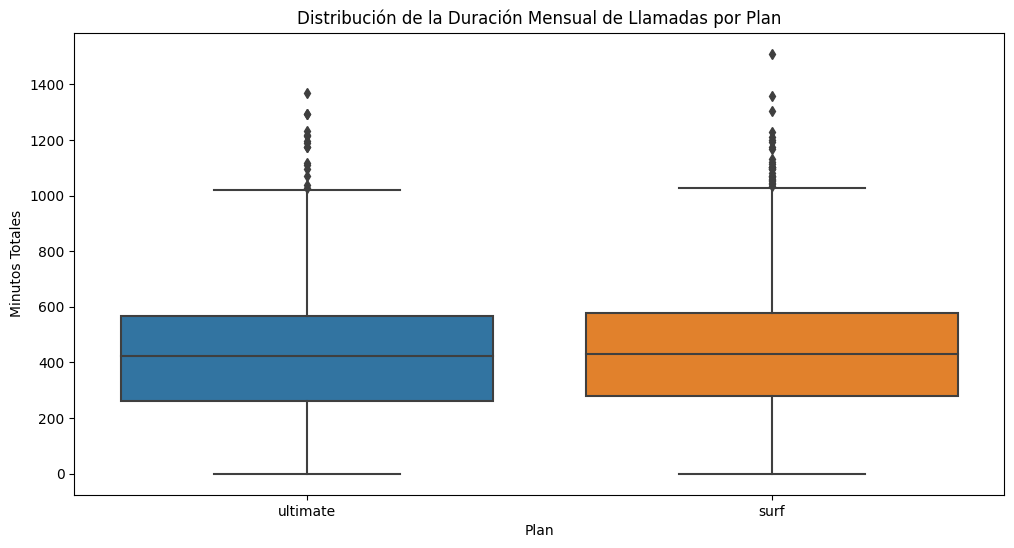

In [ ]:
# Crear el diagrama de caja
plt.figure(figsize=(12, 6))
sns.boxplot(data=datos_completos, x='plan_name', y='minutos_totales')
plt.title('Distribución de la Duración Mensual de Llamadas por Plan')
plt.xlabel('Plan')
plt.ylabel('Minutos Totales')
plt.show()

 ¿Su comportamiento varía en función del plan?

## Tomando en cuenta que en ambos planes tenemos un rango muy similar en el comportamiento de la media, solo en el caso del plan Surf tenemos precncia de valores atipicos, tambien llama la atención que estos valores se encuentran muy afuera de los minutos incluidos en dicho plan. 
## Caso contrario en el pla Ultimate, la media es apenas inferior, pero todo se encuentra dentro del consumo que se puede considerar normal a comparacion de los venficios que el plan ofrece.  

### Mensajes

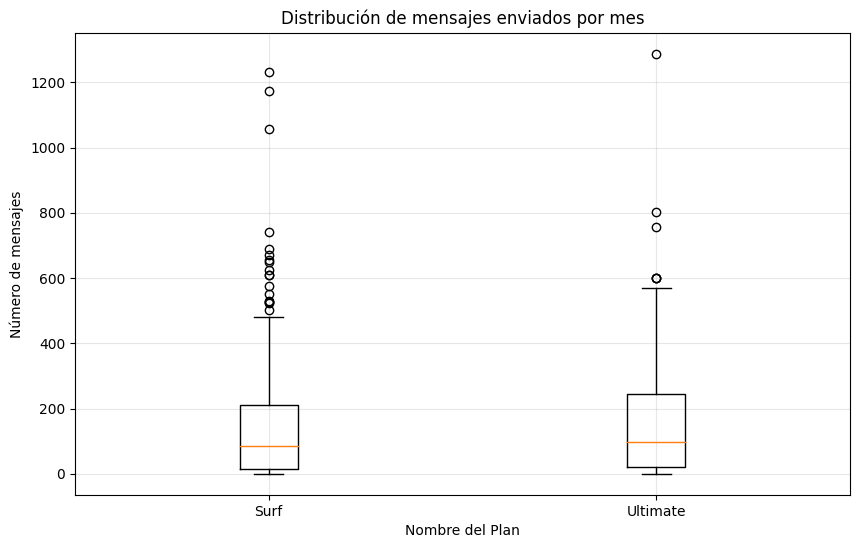

In [ ]:
# Comprara el número de mensajes que tienden a enviar cada mes los usuarios de cada plan

mensajes_mensuales = datos_completos.groupby(['user_id', 'month', 'plan_name'])['num_mensajes'].sum().reset_index()

mensajes_surf = mensajes_mensuales[mensajes_mensuales['plan_name'] == 'surf']['num_mensajes']
mensajes_ultimate = mensajes_mensuales[mensajes_mensuales['plan_name'] == 'ultimate']['num_mensajes']

plt.figure(figsize=(10, 6))
plt.boxplot([mensajes_surf, mensajes_ultimate], labels=['Surf', 'Ultimate'])
plt.title('Distribución de mensajes enviados por mes')
plt.ylabel('Número de mensajes')
plt.xlabel('Nombre del Plan')
plt.grid(True, alpha=0.3)
plt.show()



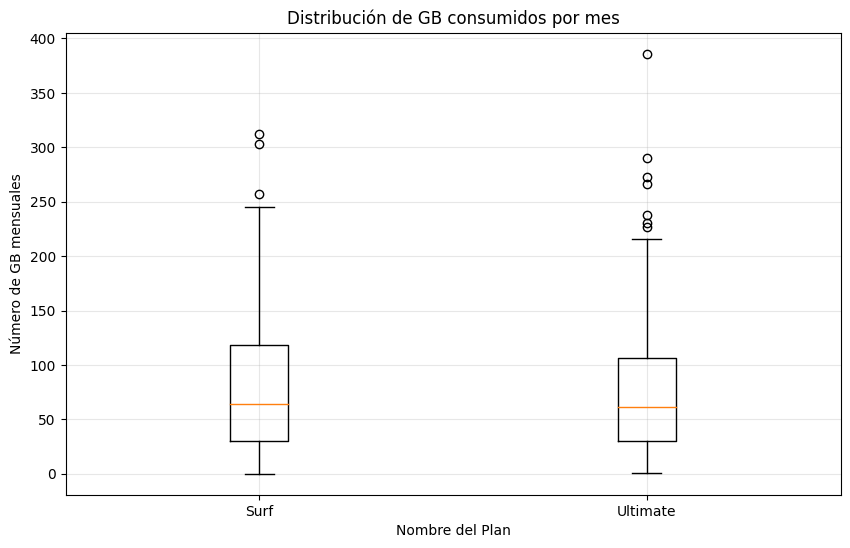

Media Surf: 78.75 GB
Media Ultimate: 79.37 GB


In [ ]:
# Compara la cantidad de tráfico de Internet consumido por usuarios por plan

gb_mensuales = datos_completos.groupby(['user_id', 'month', 'plan_name'])['gb_mensuales'].sum().reset_index()

gb_surf = gb_mensuales[gb_mensuales['plan_name'] == 'surf']['gb_mensuales']
gb_ultimate = gb_mensuales[gb_mensuales['plan_name'] == 'ultimate']['gb_mensuales']

media_surf = gb_surf.mean()
media_ultimate = gb_ultimate.mean()

plt.figure(figsize=(10, 6))
plt.boxplot([gb_surf, gb_ultimate], labels=['Surf', 'Ultimate'])
plt.title('Distribución de GB consumidos por mes')
plt.ylabel('Número de GB mensuales')
plt.xlabel('Nombre del Plan')
plt.grid(True, alpha=0.3)
plt.show()

print(f"Media Surf: {media_surf:.2f} GB")
print(f"Media Ultimate: {media_ultimate:.2f} GB")            

In [ ]:
planes_tarifas.head()

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


 ¿Su comportamiento varía en función del plan?

## El comportamiento con los mnesajes es algo que resulta sorpendente, en el plan Sur se disponen solo de 50 menjaes mensuales, pero el consumo revasa por mucho esta cifra tenemos valores atipicos que podrian considerarse muy altos, rondando entre los 140 hasta los 380 aproximadamente, incluso rosando en casos aislados los 600 mensajes. Lo cual genra un ingreso atgractivo en este plan.

## Se repite el caso en el plan Ultimate, un consumo muy bajo comparado a los veneficios que ofrece.

### Internet

In [ ]:
tarifas = {
    'surf': {'mbts':10, 'limite_mbtd':15360},
    'ultimate' : {'mbts':7, 'limite_mbts':30720}
                 }
        
datos_completos ['limite_mbts'] = datos_completos['plan_name'].map({
    'surf':15360, 
    'ultimate':30720
})
datos_completos['tarifa_mbts'] = datos_completos['plan_name'].map({
    'surf':10, 
    'ultimate':7
})

datos_completos['exceso_mbts'] =np.maximum(
    datos_completos['mb_mensuales'] - datos_completos['limite_mbts'], 0 )

datos_completos['ingreso_exceso_mbts'] =(
    datos_completos['exceso_mbts'] * datos_completos['tarifa_mbts'])

print("Columnas creadas exitosamente:")
print(datos_completos[['plan_name', 'mb_mensuales', 'limite_mbts', 'exceso_mbts', 'ingreso_exceso_mbts']].head())
    

Columnas creadas exitosamente:
  plan_name  mb_mensuales  limite_mbts  exceso_mbts  ingreso_exceso_mbts
0  ultimate       1901.47        30720         0.00                 0.00
1  ultimate       2068.37        30720         0.00                 0.00
2  ultimate      32118.82        30720      1398.82              9791.74
3  ultimate      17106.99        30720         0.00                 0.00
4  ultimate      23676.72        30720         0.00                 0.00


In [ ]:
print("=== PLAN SURF ===")
media_surf = plan_surf['mb_mensuales'].mean()
varianza_surf = plan_surf['mb_mensuales'].var()
desviacion_surf = plan_surf['mb_mensuales'].std()

print(f'Media: {media_surf:.2f} mb')
print(f'Varianza: {varianza_surf:.2f}')
print(f'Desviación estándar: {desviacion_surf:.2f}')

print("\n=== PLAN ULTIMATE ===")
media_ultimate = plan_ultimate['mb_mensuales'].mean()
varianza_ultimate = plan_ultimate['mb_mensuales'].var()
desviacion_ultimate = plan_ultimate['mb_mensuales'].std()

print(f'Media: {media_ultimate:.2f} mb')
print(f'Varianza: {varianza_ultimate:.2f}')
print(f'Desviación estándar: {desviacion_ultimate:.2f}')


=== PLAN SURF ===
Media: 16717.70 mb
Varianza: 62168225.75
Desviación estándar: 7884.68

=== PLAN ULTIMATE ===
Media: 17238.64 mb
Varianza: 61324847.98
Desviación estándar: 7831.02


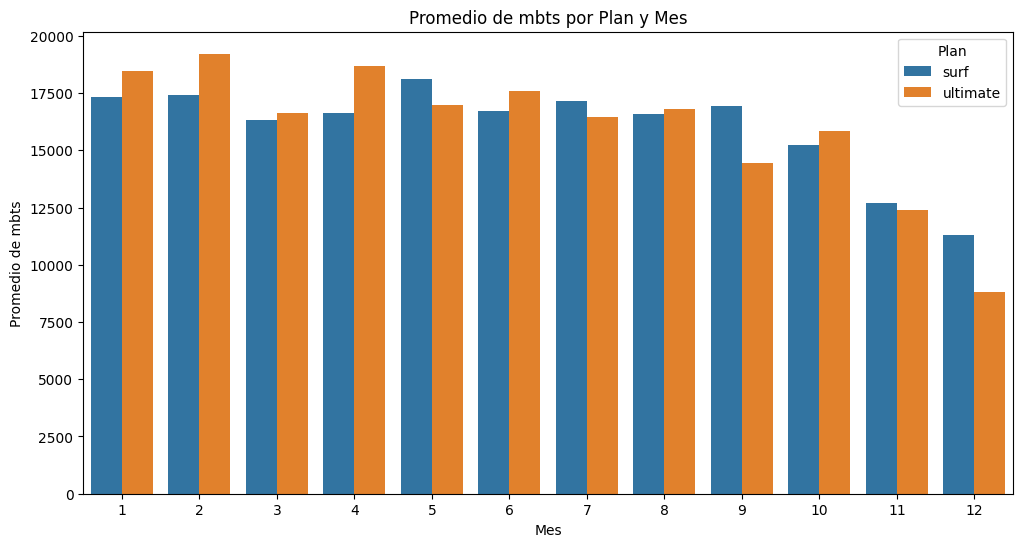

In [ ]:
datos_completos['month'] = datos_completos['reg_date'].dt.month
limite_mbts = datos_completos.groupby(['month', 'plan_name'])['mb_mensuales'].mean().reset_index()
plt.figure(figsize=(12, 6))
sns.barplot(data=limite_mbts, x='month', y='mb_mensuales', hue='plan_name')
plt.title('Promedio de mbts por Plan y Mes')
plt.xlabel('Mes')
plt.ylabel('Promedio de mbts')
plt.legend(title='Plan')
plt.show()


In [ ]:
planes_tarifas.head()

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


 ¿Su comportamiento varía en función del plan ?

## El consumo en el plan Surf, sigue reflejando un exceso, un calculo rapido, cada usuario minimo consume un GB adicional al mes y en algunos casos hasta 2 como lo muestra el mes de Julio, fin de año tiene una tenddencia a la baja, puede ser por las fiestas de fin de año, ya que la mayoria de las poersonas se queda mas tiempo en casa, conectados a su red wifi. 
## Por su parte el plan Ultimate sigue con un consumo que apenas rosa la mitad de lo que el plan ofrece.

## Ingreso

Del mismo modo que has estudiado el comportamiento de los usuarios, describe estadísticamente los ingresos de los planes.

In [ ]:
tarifas = {
    'surf': {'minutos':0.03, 'limite_minutos':500},
    'ultimate' : {'minutos':0.01, 'limite_minutos':300}
                 }
        
datos_completos ['limite_minutos'] = datos_completos['plan_name'].map({
    'surf':500, 
    'ultimate':3000
})
datos_completos['tarifa_minutos'] = datos_completos['plan_name'].map({
    'surf':0.03, 
    'ultimate':0.01
})

datos_completos['exceso_minutos'] =np.maximum(
    datos_completos['minutos_totales'] - datos_completos['limite_minutos'], 0 )

datos_completos['ingreso_exceso_minutos'] =(
    datos_completos['exceso_minutos'] * datos_completos['tarifa_minutos'])

print("Columnas creadas exitosamente:")
print(datos_completos[['plan_name', 'minutos_totales', 'limite_minutos', 'exceso_minutos', 'ingreso_exceso_minutos']].head())


Columnas creadas exitosamente:
  plan_name  minutos_totales  limite_minutos  exceso_minutos  \
0  ultimate            124.0            3000             0.0   
1  ultimate             10.0            3000             0.0   
2  ultimate             59.0            3000             0.0   
3  ultimate            476.0            3000             0.0   
4  ultimate            446.0            3000             0.0   

   ingreso_exceso_minutos  
0                     0.0  
1                     0.0  
2                     0.0  
3                     0.0  
4                     0.0  


In [ ]:
tarifas = {
    'surf': {'mbts':10, 'limite_mbtd':15360},
    'ultimate' : {'mbts':7, 'limite_mbts':30720}
                 }
        
datos_completos ['limite_mbts'] = datos_completos['plan_name'].map({
    'surf':15360, 
    'ultimate':30720
})
datos_completos['tarifa_mbts'] = datos_completos['plan_name'].map({
    'surf':10, 
    'ultimate':7
})

datos_completos['exceso_mbts'] =np.maximum(
    datos_completos['mb_mensuales'] - datos_completos['limite_mbts'], 0 )

datos_completos['ingreso_exceso_mbts'] =(
    datos_completos['exceso_mbts'] * datos_completos['tarifa_mbts'])

print("Columnas creadas exitosamente:")
print(datos_completos[['plan_name', 'mb_mensuales', 'limite_mbts', 'exceso_mbts', 'ingreso_exceso_mbts']].head())


Columnas creadas exitosamente:
  plan_name  mb_mensuales  limite_mbts  exceso_mbts  ingreso_exceso_mbts
0  ultimate       1901.47        30720         0.00                 0.00
1  ultimate       2068.37        30720         0.00                 0.00
2  ultimate      32118.82        30720      1398.82              9791.74
3  ultimate      17106.99        30720         0.00                 0.00
4  ultimate      23676.72        30720         0.00                 0.00


In [ ]:
tarifas = {
    'surf': {'mensajes':0.03, 'limite_minutos':50},
    'ultimate' : {'mensajes':0.01, 'limite_mensajes':1000}
                 }
        
datos_completos ['limite_mensajes'] = datos_completos['plan_name'].map({
    'surf':50, 
    'ultimate':1000
})
datos_completos['tarifa_mensajes'] = datos_completos['plan_name'].map({
    'surf':0.03, 
    'ultimate':0.01
})

datos_completos['exceso_mensajes'] =np.maximum(
    datos_completos['num_mensajes'] - datos_completos['limite_mensajes'], 0 )

datos_completos['ingreso_exceso_mensajes'] =(
    datos_completos['exceso_mensajes'] * datos_completos['tarifa_mensajes'])

print("Columnas creadas exitosamente:")
print(datos_completos[['plan_name', 'num_mensajes', 'limite_mensajes', 'exceso_mensajes', 'ingreso_exceso_mensajes']].head())


Columnas creadas exitosamente:
  plan_name  num_mensajes  limite_mensajes  exceso_mensajes  \
0  ultimate          11.0             1000              0.0   
1  ultimate          15.0             1000              0.0   
2  ultimate         139.0             1000              0.0   
3  ultimate          21.0             1000              0.0   
4  ultimate          37.0             1000              0.0   

   ingreso_exceso_mensajes  
0                      0.0  
1                      0.0  
2                      0.0  
3                      0.0  
4                      0.0  


In [ ]:

print("=== INGRESOS PLAN SURF ===")
ingresos_surf = datos_completos[datos_completos['plan_name'] == 'surf']['revenue'].mean()
print(f'Ingreso promedio: ${ingresos_surf:.2f}')

print("=== INGRESOS PLAN ULTIMATE ===")
ingresos_ultimate = datos_completos[datos_completos['plan_name'] == 'ultimate']['revenue'].mean()
print(f'Ingreso promedio: ${ingresos_ultimate:.2f}')

=== INGRESOS PLAN SURF ===
Ingreso promedio: $60.71
=== INGRESOS PLAN ULTIMATE ===
Ingreso promedio: $72.31


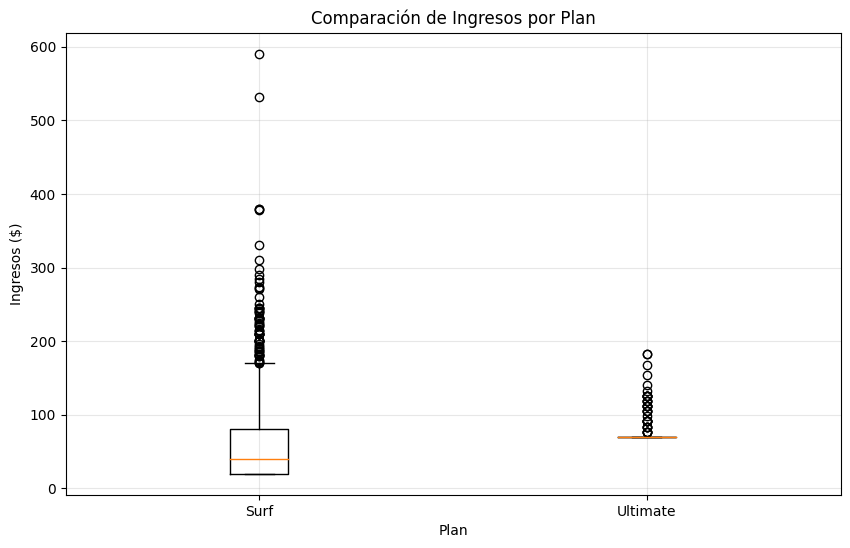

In [ ]:
ingresos_surf = datos_completos[datos_completos['plan_name'] == 'surf']['revenue']
ingresos_ultimate = datos_completos[datos_completos['plan_name'] == 'ultimate']['revenue']

# Crear el boxplot
plt.figure(figsize=(10, 6))
plt.boxplot([ingresos_surf, ingresos_ultimate], 
            labels=['Surf', 'Ultimate'])
plt.title('Comparación de Ingresos por Plan')
plt.ylabel('Ingresos ($)')
plt.xlabel('Plan')
plt.grid(True, alpha=0.3)
plt.show()

conclusiones sobre cómo difiere el ingreso entre los planes
## Puedo ver que el ingreso promedio del plan 'Surf' es mayor que el plan 'Ultimate'

## Prueba las hipótesis estadísticas

Prueba la hipótesis de que son diferentes los ingresos promedio procedentes de los usuarios de los planes de llamada Ultimate y Surf.

Elabora las hipótesis nula y alternativa, escoge la prueba estadística, determina el valor alfa.

In [ ]:
# Prueba las hipótesis

# 1. Definir hipótesis
print("Hipotesis nula: Los ingresos promedio de Ultimate y Surf son iguales")
print("Hipotesis alternativa: Los ingresos promedio de Ultimate y Surf son diferentes")
print("αlpha = 0.05")

# 2. Preparar los datos
ingresos_surf = datos_completos[datos_completos['plan_name'] == 'surf']['revenue']
ingresos_ultimate = datos_completos[datos_completos['plan_name'] == 'ultimate']['revenue']

# 3. Realizar la prueba t
from scipy import stats
t_stat, p_valor = stats.ttest_ind(ingresos_ultimate, ingresos_surf)

# 4. Interpretar resultados
print(f"Estadístico t: {t_stat:.4f}")
print(f"P-valor: {p_valor:.4f}")

if p_valor < 0.05:
    print("Rechazamos Hipotesis nula: Hay diferencia significativa en los ingresos")
else:
    print("No rechazamos Hipoteisis nula: No hay evidencia de diferencia significativa")

Hipotesis nula: Los ingresos promedio de Ultimate y Surf son iguales
Hipotesis alternativa: Los ingresos promedio de Ultimate y Surf son diferentes
αlpha = 0.05
Estadístico t: 5.5689
P-valor: 0.0000
Rechazamos Hipotesis nula: Hay diferencia significativa en los ingresos


Prueba la hipótesis de que el ingreso promedio de los usuarios del área NY-NJ es diferente al de los usuarios de otras regiones.

Elabora las hipótesis nula y alternativa, escoge la prueba estadística, determina el valor alfa.

In [ ]:
print("Ciudades disponibles en los datos:")
print(datos_completos['city'].unique())


Ciudades disponibles en los datos:
['Atlanta-Sandy Springs-Roswell, GA MSA'
 'San Francisco-Oakland-Berkeley, CA MSA'
 'Orlando-Kissimmee-Sanford, FL MSA' 'Cleveland-Elyria, OH MSA'
 'Knoxville, TN MSA' 'Houston-The Woodlands-Sugar Land, TX MSA'
 'Philadelphia-Camden-Wilmington, PA-NJ-DE-MD MSA'
 'Chicago-Naperville-Elgin, IL-IN-WI MSA'
 'New York-Newark-Jersey City, NY-NJ-PA MSA' 'Birmingham-Hoover, AL MSA'
 'Oklahoma City, OK MSA' 'Denver-Aurora-Lakewood, CO MSA'
 'Seattle-Tacoma-Bellevue, WA MSA'
 'Nashville-Davidson–Murfreesboro–Franklin, TN MSA' 'Columbus, OH MSA'
 'Las Vegas-Henderson-Paradise, NV MSA'
 'Indianapolis-Carmel-Anderson, IN MSA'
 'Miami-Fort Lauderdale-West Palm Beach, FL MSA' 'Columbia, SC MSA'
 'San Antonio-New Braunfels, TX MSA'
 'Charlotte-Concord-Gastonia, NC-SC MSA' 'Phoenix-Mesa-Chandler, AZ MSA'
 'Riverside-San Bernardino-Ontario, CA MSA'
 'Grand Rapids-Kentwood, MI MSA' 'New Haven-Milford, CT MSA'
 'Cincinnati, OH-KY-IN MSA'
 'Virginia Beach-Norfolk-Newport 

In [ ]:
# Prueba las hipótesis

print("Buscando ciudades que contengan 'New York':")
ny_cities = [city for city in datos_completos['city'].unique() if 'New York' in city]
print(ny_cities)

ciudad_ny_nj = 'New York-Newark-Jersey City, NY-NJ-PA MSA'  # Nombre completo

ny_nj_ingresos = datos_completos[datos_completos['city'] == ciudad_ny_nj]['revenue']
otras_ciudades_ingresos = datos_completos[datos_completos['city'] != ciudad_ny_nj]['revenue']

statistic, p_value = stats.ttest_ind(ny_nj_ingresos, otras_ciudades_ingresos)

alpha = 0.05  

print(f"Estadístico t: {statistic:.4f}")
print(f"P-valor: {p_value:.4f}")


if p_value < alpha:
    print("Rechazamos Hipótesis nula: Hay diferencia significativa")
else:
    print("No rechazamos Hipótesis nula: No hay evidencia de diferencia")


Buscando ciudades que contengan 'New York':
['New York-Newark-Jersey City, NY-NJ-PA MSA']
Estadístico t: -2.0194
P-valor: 0.0436
Rechazamos Hipótesis nula: Hay diferencia significativa


## Conclusión general

## En conclucion, los ingresos que deja el plan Surf reflejan que esta tarifa debe seguir siendo empujada al consumidor, ya que los veneficios inmediatos para la compañia seran constantes, el plan Ultimate puede seguir figurando ya que es un metodo seguro de generar ganacias ya que siempre quedaran recursos(minutos, mensajes, mb) a favor de la empresa, y estos no seran rembolsados ni descontados de facturas siguentes.

## Afortunadamente, los datasets fueron faciles de procesar, y con la informacion necesaria para la elaboracion de calculos y graficos necesarios para la busqueda de informacion. 
